In [1]:
!pip install langchain-ollama

In [14]:
from langchain_ollama import ChatOllama
from langchain_community.tools.tavily_search import TavilySearchResults
from langchain.agents import initialize_agent
search_tool = TavilySearchResults(max_results=2)

llm = ChatOllama(model="llama3.2")
llm.bind_tools([search_tool])
llm.invoke("search from web about IPL")

AIMessage(content='The Indian Premier League (IPL) is a professional Twenty20 cricket league in India. Here are some key facts and information about the IPL:\n\n**History**\n\nThe first edition of the IPL was held in 2008, and it was founded by the Board of Control for Cricket in India (BCCI). The tournament was initially sponsored by PepsiCo, but since then, several other brands have been associated with the league.\n\n**Structure**\n\nThe IPL typically features eight teams, each representing a different city or state in India. The tournament is divided into two groups: Qualifier 1 and Qualifier 2, which determine the final two teams that compete for the title. There are also two qualifying matches between teams from different groups to reach the play-off stage.\n\n**Format**\n\nThe IPL is a Twenty20 format league, meaning each match is played over 20 overs (120 balls). The team with the higher aggregate score at the end of the match wins. If the scores are tied, there can be one-over

In [15]:
from langchain_groq import ChatGroq
from IPython.display import display, Image


# llm = ChatOllama(model="llama3.2")

In [16]:
from typing_extensions import List, TypedDict
from pydantic import BaseModel, Field

class Analyst(BaseModel):
    affiliation: str = Field(
        description="Primary affiliation of the analyst.",
    )
    name: str = Field(
        description="Name of the analyst."
    )
    role: str = Field(
        description="Role of the analyst in the context of the topic.",
    )
    description: str = Field(
        description="Description of the analyst focus, concerns, and motives.",
    )
    @property
    def persona(self) -> str:
        return f"Name: {self.name}\nRole: {self.role}\nAffiliation: {self.affiliation}\nDescription: {self.description}\n"

class Perspectives(BaseModel):
    analysts : List[Analyst] = Field(
        description="List of analysts with their role and affiliation."
    )

# generate analyst state
class GenerateAnalystState(TypedDict):
  topic: str # research topic
  max_analyst: int # No of Analysts
  human_analyst_feedback : str # Feedback by human
  analysts: List[Analyst] # List of analyst asking questions

In [17]:
from langgraph.graph import StateGraph, START, END
from langgraph.checkpoint.memory import MemorySaver
from langchain_core.messages import AIMessage,HumanMessage,SystemMessage

analyst_instructions="""You are tasked with creating a set of AI analyst personas. Follow these instructions carefully:

1. First, review the research topic:
{topic}

2. Examine any editorial feedback that has been optionally provided to guide creation of the analysts:

{human_analyst_feedback}

3. Determine the most interesting themes based upon documents and / or feedback above.

4. Pick the top {max_analyst} themes.

5. Assign one analyst to each theme."""

def create_analyst(state: GenerateAnalystState):
  """Create Analyst"""
  topic = state["topic"]
  max_analyst = state['max_analyst']
  human_analyst_feedback = state.get('human_analyst_feedback','')

  # enforce structured output
  structured_llm = llm.with_structured_output(Perspectives)

  system_message = analyst_instructions.format(topic=topic,max_analyst=max_analyst,human_analyst_feedback=human_analyst_feedback)
  final_message = [SystemMessage(content=system_message)]+[HumanMessage(content="Generate the set of Analysts")]
  analysts = structured_llm.invoke(final_message)
  return {
      'analysts':analysts.analysts
  }


def human_feedback(state: GenerateAnalystState):
    """ No-op node that should be interrupted on """
    pass

In [18]:
def should_continue(state:GenerateAnalystState):
  "Returns the next node to execute"
  human_analyst_feedback = state.get('human_analyst_feedback',None)
  if human_analyst_feedback:
    return 'create_analyst'
  
  return END

In [19]:
# Add nodes and edges
bd = StateGraph(GenerateAnalystState)

bd.add_node("create_analyst",create_analyst)
bd.add_node("human_feedback",human_feedback)

bd.add_edge(START, "create_analyst")
bd.add_edge("create_analyst", "human_feedback")
bd.add_conditional_edges("human_feedback", should_continue,['create_analyst',END])

memory = MemorySaver()

graph = bd.compile(interrupt_before=["human_feedback"],checkpointer=memory)


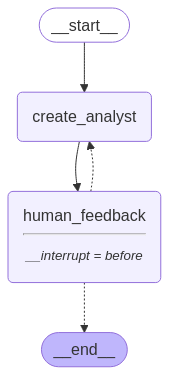

In [20]:
display(Image(graph.get_graph(xray=1).draw_mermaid_png()))

In [23]:
# Input
max_analysts = 3
topic = "The benefits of adopting LangGraph as an agent framework"
thread = {"configurable": {"thread_id": "1"}}

# Run the graph until the first interruption
for event in graph.stream({"topic":topic,"max_analyst":max_analysts,}, thread, stream_mode="values"):
    # Review
    analysts = event.get('analysts', '')
    if analysts:
        for analyst in analysts:
            print(f"Name: {analyst.name}")
            print(f"Affiliation: {analyst.affiliation}")
            print(f"Role: {analyst.role}")
            print(f"Description: {analyst.description}")
            print("-" * 50)  

ValidationError: 6 validation errors for Perspectives
analysts.0.name
  Field required [type=missing, input_value={'role': 'AI Model Evalua...affiliation': 'Meta AI'}, input_type=dict]
    For further information visit https://errors.pydantic.dev/2.10/v/missing
analysts.0.description
  Field required [type=missing, input_value={'role': 'AI Model Evalua...affiliation': 'Meta AI'}, input_type=dict]
    For further information visit https://errors.pydantic.dev/2.10/v/missing
analysts.1.name
  Field required [type=missing, input_value={'role': 'Natural Languag...': 'Stanford NLP Group'}, input_type=dict]
    For further information visit https://errors.pydantic.dev/2.10/v/missing
analysts.1.description
  Field required [type=missing, input_value={'role': 'Natural Languag...': 'Stanford NLP Group'}, input_type=dict]
    For further information visit https://errors.pydantic.dev/2.10/v/missing
analysts.2.name
  Field required [type=missing, input_value={'role': 'Machine Learnin...n': 'Google 